<a href="https://colab.research.google.com/github/ilyassboudrioua/qr-shield-mlops/blob/main/notebooks/01_links_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
DATA = '/content/drive/MyDrive/QR-Shield/data'
MODELS = '/content/drive/MyDrive/QR-Shield/models'

# Sauvegarder les données déjà téléchargées
os.makedirs(f"{DATA}/links", exist_ok=True)
train_df.to_csv(f"{DATA}/links/train.csv", index=False)
test_df.to_csv(f"{DATA}/links/test.csv", index=False)

# Vérifier
print("Train :", train_df.shape, "| Test :", test_df.shape)
print(train_df["label"].value_counts(normalize=True).round(3))
print("Dates train :", train_df["date"].min(), "→", train_df["date"].max())
print("Dates test  :", test_df["date"].min(), "→", test_df["date"].max())
train_df.head()

Mounted at /content/drive
Train : (100000, 3) | Test : (30000, 3)
label
benign    0.556
phish     0.444
Name: proportion, dtype: float64
Dates train : 2024-07-02 → 2025-09-08
Dates test  : 2025-09-08 → 2025-12-16


,url,label,date
0,https://accvrtf-mnages019.tivinalili.com.br/?v...,phish,2025-07-30
1,https://bellagio.mgmresorts.com/en/entertainme...,benign,2025-08-21
2,https://informed.deliverywup.top/us/,phish,2025-01-09
3,http://advertisinghelpcenter68.click/,phish,2025-01-06
4,https://www.blundstone.com/mens-chelsea-boots,benign,2025-08-18


In [ ]:
from datasets import load_dataset
import pandas as pd

# 1. Lire le dataset en flux, en gardant seulement 3 colonnes
cols = ["url", "label", "date"]
train_stream = load_dataset("phreshphish/phreshphish", split="train", streaming=True, columns=cols)
test_stream  = load_dataset("phreshphish/phreshphish", split="test",  streaming=True, columns=cols)

# 2. Prendre un échantillon mélangé
train_df = pd.DataFrame(list(train_stream.shuffle(seed=42, buffer_size=10_000).take(100_000)))
test_df  = pd.DataFrame(list(test_stream.shuffle(seed=42, buffer_size=10_000).take(30_000)))

# 3. Enregistrer dans le Drive
os.makedirs(f"{DATA}/links", exist_ok=True)
train_df.to_csv(f"{DATA}/links/train.csv", index=False)
test_df.to_csv(f"{DATA}/links/test.csv", index=False)

# 4. Vérifier
print("Train :", train_df.shape, "| Test :", test_df.shape)
print(train_df["label"].value_counts(normalize=True).round(3))
print("Dates train :", train_df["date"].min(), "→", train_df["date"].max())
print("Dates test  :", test_df["date"].min(), "→", test_df["date"].max())
train_df.head()

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

Train : (100000, 3) | Test : (30000, 3)
label
benign    0.556
phish     0.444
Name: proportion, dtype: float64
Dates train : 2024-07-02 → 2025-09-08
Dates test  : 2025-09-08 → 2025-12-16


,url,label,date
0,https://accvrtf-mnages019.tivinalili.com.br/?v...,phish,2025-07-30
1,https://bellagio.mgmresorts.com/en/entertainme...,benign,2025-08-21
2,https://informed.deliverywup.top/us/,phish,2025-01-09
3,http://advertisinghelpcenter68.click/,phish,2025-01-06
4,https://www.blundstone.com/mens-chelsea-boots,benign,2025-08-18


In [ ]:
print("1. Doublons")
print("Train :", train_df.duplicated(subset="url").sum(), "| Test :", test_df.duplicated(subset="url").sum())

print("\n2. Labels contradictoires (même URL, deux labels)")
conflits = train_df.groupby("url")["label"].nunique()
print("URLs en conflit :", (conflits > 1).sum())

print("\n3. Valeurs manquantes")
print(train_df.isna().sum().to_dict())

print("\n4. Valeurs impossibles")
print("URLs vides :", (train_df["url"].str.strip() == "").sum())
print("URLs sans http(s) :", (~train_df["url"].str.startswith(("http://", "https://"))).sum())

print("\n5. Colonnes constantes")
print(train_df.nunique().to_dict())

print("\n6. Fuite : URLs présentes dans train ET test")
communes = set(train_df["url"]) & set(test_df["url"])
print("URLs communes :", len(communes))

1. Doublons
Train : 0 | Test : 0

2. Labels contradictoires (même URL, deux labels)
URLs en conflit : 0

3. Valeurs manquantes
{'url': 0, 'label': 0, 'date': 0}

4. Valeurs impossibles
URLs vides : 0
URLs sans http(s) : 846

5. Colonnes constantes
{'url': 100000, 'label': 2, 'date': 391}

6. Fuite : URLs présentes dans train ET test
URLs communes : 0


## Étape 3.2 : Analyse des URLs sans http(s)

Le diagnostic a trouvé 846 URLs qui ne commencent pas par `http://` ou `https://` (moins de 1 % du train).
On vérifie leur label et leur forme, pour éviter un **raccourci (shortcut)** :
si elles sont presque toutes du phishing, le modèle risque d'apprendre « pas de http = phishing »,
ce qui est un détail du dataset et non un vrai signe d'attaque.

In [ ]:
sans_http = train_df[~train_df["url"].str.startswith(("http://", "https://"))]

print("Répartition des labels :")
print(sans_http["label"].value_counts())

print("\nComment elles commencent :")
print(sans_http["url"].str.extract(r"^([a-zA-Z]+:)?")[0].value_counts(dropna=False).head(10))

print("\nExemples :")
print(sans_http["url"].sample(10, random_state=42).to_string())

Répartition des labels :
label
benign    846
Name: count, dtype: int64

Comment elles commencent :
0
NaN    846
Name: count, dtype: int64

Exemples :
5457                        chat.google.com/u/6/mole/world
32147    s0.2mdn.net/sadbundle/11177038917899538476/ind...
39113     www.fivestarisuzu.com/product/2012-isuzu-npr-hd/
12114                         www.instagram.com/aninebing/
24579    search.rakuten.co.jp/search/mall/%E5%B9%B4%E9%...
13569                          www.google.com/maps/preview
40891           local.fedex.com/en-us/nd/fargo/office-0566
38625                           www.express-scripts.com/rx
54771    www.centresuite.com/centre/statements/reviewac...
54359                  games.aarp.org/games/easy-crossword


## Étape 3.3 : Nettoyage

**Constat :** les 846 URLs sans `http(s)://` sont toutes `benign`.
Les garder créerait un raccourci : le modèle apprendrait « pas de http = site sûr ».
On ne peut pas deviner si c'était `http` ou `https`, et elles représentent moins de 1 % des données.

**Décision :** on les supprime du train et du test, puis on sauvegarde les données propres.

In [ ]:
# Garder seulement les URLs qui commencent par http:// ou https://
def garder_http(df):
    return df[df["url"].str.startswith(("http://", "https://"))].reset_index(drop=True)

avant_train, avant_test = len(train_df), len(test_df)
train_clean = garder_http(train_df)
test_clean = garder_http(test_df)

print("Train :", avant_train, "→", len(train_clean), f"({avant_train - len(train_clean)} supprimées)")
print("Test  :", avant_test, "→", len(test_clean), f"({avant_test - len(test_clean)} supprimées)")

# Vérifier que l'équilibre des classes n'a presque pas bougé
print("\nLabels train :")
print(train_clean["label"].value_counts(normalize=True).round(3))

# Sauvegarder les versions propres dans le Drive
train_clean.to_csv(f"{DATA}/links/train_clean.csv", index=False)
test_clean.to_csv(f"{DATA}/links/test_clean.csv", index=False)
print("\nFichiers propres sauvegardés")

Train : 100000 → 99154 (846 supprimées)
Test  : 30000 → 29711 (289 supprimées)

Labels train :
label
benign    0.552
phish     0.448
Name: proportion, dtype: float64

Fichiers propres sauvegardés


## Étape 4 : Création des features (module liens)

Un modèle ne lit pas du texte, il lit des nombres.
On transforme donc chaque URL en une ligne de features simples :
longueur, nombre de points, de tirets et de chiffres, présence de "@", adresse IP à la place du nom,
HTTPS, nombre de sous-domaines, entropie (mesure du désordre des caractères)
et nombre de mots suspects (login, verify, account...).
Le label devient 1 pour phishing et 0 pour benign.

In [ ]:
import re, math
from urllib.parse import urlparse
from collections import Counter

MOTS_SUSPECTS = ["login", "verify", "account", "update", "secure", "bank",
                 "signin", "confirm", "password", "wallet", "support", "billing"]

def entropie(texte):
    if not texte:
        return 0.0
    freq = Counter(texte)
    return -sum((n / len(texte)) * math.log2(n / len(texte)) for n in freq.values())

def features_url(url):
    p = urlparse(url)
    host = p.hostname or ""
    return {
        "longueur_url": len(url),
        "longueur_host": len(host),
        "longueur_chemin": len(p.path),
        "nb_points": url.count("."),
        "nb_tirets": url.count("-"),
        "nb_chiffres": sum(c.isdigit() for c in url),
        "nb_sous_domaines": max(host.count(".") - 1, 0),
        "a_arobase": int("@" in url),
        "host_est_ip": int(bool(re.fullmatch(r"\d{1,3}(\.\d{1,3}){3}", host))),
        "https": int(p.scheme == "https"),
        "nb_parametres": len(p.query.split("&")) if p.query else 0,
        "entropie": round(entropie(url), 3),
        "nb_mots_suspects": sum(m in url.lower() for m in MOTS_SUSPECTS),
    }

def construire(df):
    X = pd.DataFrame([features_url(u) for u in df["url"]])
    y = (df["label"] == "phish").astype(int)
    return X, y

X_train, y_train = construire(train_clean)
X_test, y_test = construire(test_clean)

print("X_train :", X_train.shape, "| X_test :", X_test.shape)

# Moyenne de chaque feature selon la classe (0 = benign, 1 = phish)
X_train.groupby(y_train).mean().round(2).T

X_train : (99154, 13) | X_test : (29711, 13)


label,0,1
longueur_url,61.07,52.38
longueur_host,17.53,25.04
longueur_chemin,35.55,15.18
nb_points,2.12,2.06
nb_tirets,2.45,1.20
nb_chiffres,3.04,5.26
nb_sous_domaines,0.94,0.86
a_arobase,0.00,0.01
host_est_ip,0.00,0.00
https,0.99,0.87


## Étape 5 : Baseline (Logistic Regression)

On commence toujours par un modèle simple, la baseline. Elle sert de point de comparaison :
le modèle principal (XGBoost) devra faire mieux qu'elle.

Comme vu en cours, on utilise 3 ensembles : train (apprendre), validation (régler et comparer), test (mesurer une seule fois à la fin).
On découpe donc le train par date : les 80 % les plus anciens pour apprendre, les 20 % les plus récents pour la validation.
Le test n'est pas touché à cette étape.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (confusion_matrix, recall_score, precision_score, f1_score,
                             matthews_corrcoef, roc_auc_score, average_precision_score)

# 1. Découper le train en train / validation selon la date
dates = pd.to_datetime(train_clean["date"])
coupure = dates.quantile(0.8)
est_val = dates > coupure
X_tr, y_tr = X_train[~est_val], y_train[~est_val]
X_val, y_val = X_train[est_val], y_train[est_val]
print("Coupure :", coupure.date(), "| Train :", len(X_tr), "| Validation :", len(X_val))

# 2. Entraîner la baseline (normalisation + régression logistique)
baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
baseline.fit(X_tr, y_tr)

# 3. Évaluer sur la validation, avec le seuil par défaut de 0,5
proba = baseline.predict_proba(X_val)[:, 1]
pred = (proba >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

print(f"\nTP={tp}  FN={fn}  FP={fp}  TN={tn}")
print("Recall    :", round(recall_score(y_val, pred), 3))
print("Precision :", round(precision_score(y_val, pred), 3))
print("F1-score  :", round(f1_score(y_val, pred), 3))
print("FPR       :", round(fp / (fp + tn), 3))
print("MCC       :", round(matthews_corrcoef(y_val, pred), 3))
print("ROC-AUC   :", round(roc_auc_score(y_val, proba), 3))
print("PR-AUC    :", round(average_precision_score(y_val, proba), 3))

Coupure : 2025-07-10 | Train : 79674 | Validation : 19480

TP=3846  FN=1741  FP=2086  TN=11807
Recall    : 0.688
Precision : 0.648
F1-score  : 0.668
FPR       : 0.15
MCC       : 0.529
ROC-AUC   : 0.795
PR-AUC    : 0.772


## Étape 5.2 : Modèle principal (XGBoost)

XGBoost construit des centaines de petits arbres de décision, chacun corrigeant les erreurs des précédents.
Contrairement à la baseline, il capte des règles non linéaires,
par exemple « nom de site long ET pas de HTTPS ET beaucoup de chiffres ».
On l'entraîne sur les mêmes données et on le compare à la baseline sur la même validation.

In [ ]:
from xgboost import XGBClassifier

# Fonction pour calculer toutes les métriques d'un modèle (évite de répéter le code)
def evaluer(nom, y_vrai, proba, seuil=0.5):
    pred = (proba >= seuil).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_vrai, pred).ravel()
    return {"Modèle": nom, "TP": tp, "FN": fn, "FP": fp, "TN": tn,
            "Recall": recall_score(y_vrai, pred), "Precision": precision_score(y_vrai, pred),
            "F1": f1_score(y_vrai, pred), "FPR": fp / (fp + tn),
            "MCC": matthews_corrcoef(y_vrai, pred),
            "ROC-AUC": roc_auc_score(y_vrai, proba), "PR-AUC": average_precision_score(y_vrai, proba)}

# Entraîner XGBoost
xgb = XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.1,
                    subsample=0.8, colsample_bytree=0.8,
                    eval_metric="logloss", random_state=42, n_jobs=-1)
xgb.fit(X_tr, y_tr)

# Comparer baseline et XGBoost sur la validation
resultats = pd.DataFrame([
    evaluer("Baseline (LogReg)", y_val, baseline.predict_proba(X_val)[:, 1]),
    evaluer("XGBoost", y_val, xgb.predict_proba(X_val)[:, 1]),
]).set_index("Modèle")
resultats.round(3)

,TP,FN,FP,TN,Recall,Precision,F1,FPR,MCC,ROC-AUC,PR-AUC
Modèle,,,,,,,,,,,
Baseline (LogReg),3846,1741,2086,11807,0.688,0.648,0.668,0.150,0.529,0.795,0.772
XGBoost,4020,1567,960,12933,0.720,0.807,0.761,0.069,0.674,0.877,0.846


## Étape 5.3 : Ajout des n-grammes de caractères (TF-IDF)

Les 13 features décrivent la forme de l'URL, mais pas son contenu.
On découpe donc chaque URL en petits morceaux de 3 à 5 caractères (n-grammes),
par exemple "paypal-login" donne "pay", "ayp", "ypa", ... "log", "ogi", "gin".
Le TF-IDF donne un poids à chaque morceau : fort s'il est rare, faible s'il est présent partout (comme "www" ou ".com").
On garde les 20 000 morceaux les plus fréquents et on les ajoute aux 13 features.

Règle du cours : le TF-IDF est appris uniquement sur le train, jamais sur la validation ni sur le test.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack, csr_matrix

# Les URLs correspondant à chaque partie
urls_tr = train_clean["url"][~est_val]
urls_val = train_clean["url"][est_val]

# 1. Apprendre le vocabulaire TF-IDF sur le train seulement
tfidf = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5),
                        max_features=20000, min_df=5, lowercase=True)
T_tr = tfidf.fit_transform(urls_tr)
T_val = tfidf.transform(urls_val)

# 2. Coller les 13 features + les 20 000 colonnes TF-IDF
Xc_tr = hstack([csr_matrix(X_tr.values), T_tr]).tocsr()
Xc_val = hstack([csr_matrix(X_val.values), T_val]).tocsr()
print("Taille train :", Xc_tr.shape, "| Taille validation :", Xc_val.shape)

# 3. Entraîner XGBoost sur l'ensemble
xgb_tfidf = XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.1,
                          subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                          eval_metric="logloss", random_state=42, n_jobs=-1)
xgb_tfidf.fit(Xc_tr, y_tr)

# 4. Comparer les 3 modèles
resultats = pd.concat([resultats, pd.DataFrame([
    evaluer("XGBoost + TF-IDF", y_val, xgb_tfidf.predict_proba(Xc_val)[:, 1])
]).set_index("Modèle")])
resultats.round(3)

Taille train : (79674, 20013) | Taille validation : (19480, 20013)


,TP,FN,FP,TN,Recall,Precision,F1,FPR,MCC,ROC-AUC,PR-AUC
Modèle,,,,,,,,,,,
Baseline (LogReg),3846,1741,2086,11807,0.688,0.648,0.668,0.150,0.529,0.795,0.772
XGBoost,4020,1567,960,12933,0.720,0.807,0.761,0.069,0.674,0.877,0.846
XGBoost + TF-IDF,4198,1389,292,13601,0.751,0.935,0.833,0.021,0.784,0.910,0.889


## Étape 6.1 : Choix du seuil

Par défaut, le modèle dit "phishing" si son score dépasse 0,5. Ce seuil n'est pas forcément le bon.
On applique la méthode du cours en 4 étapes :
1. Connaître le budget : on accepte au maximum 5 % de fausses alertes.
2. Le traduire en FPR : FPR ≤ 0,05.
3. Fixer le seuil sur la validation : le seuil qui donne le meilleur rappel avec un FPR ≤ 5 %.
4. Mesurer une seule fois sur le test (étape suivante).

In [ ]:
from sklearn.metrics import roc_curve

proba_val = xgb_tfidf.predict_proba(Xc_val)[:, 1]

# 1-2. Budget : FPR maximal accepté
FPR_MAX = 0.05

# 3. Chercher le seuil qui donne le meilleur rappel avec FPR <= 5 %
fpr, tpr, seuils = roc_curve(y_val, proba_val)
ok = fpr <= FPR_MAX
i = tpr[ok].argmax()
SEUIL = float(seuils[ok][i])
print(f"Seuil choisi : {SEUIL:.3f}  |  Recall : {tpr[ok][i]:.3f}  |  FPR : {fpr[ok][i]:.3f}")

# Comparer quelques seuils pour voir le compromis
tableau = pd.DataFrame([evaluer(f"Seuil {s:.2f}", y_val, proba_val, seuil=s)
                        for s in [0.5, 0.4, 0.3, 0.2, SEUIL]]).set_index("Modèle")
tableau[["TP", "FN", "FP", "Recall", "Precision", "FPR", "MCC"]].round(3)

Seuil choisi : 0.221  |  Recall : 0.796  |  FPR : 0.050


,TP,FN,FP,Recall,Precision,FPR,MCC
Modèle,,,,,,,
Seuil 0.50,4198,1389,292,0.751,0.935,0.021,0.784
Seuil 0.40,4290,1297,395,0.768,0.916,0.028,0.782
Seuil 0.30,4383,1204,539,0.784,0.890,0.039,0.776
Seuil 0.20,4457,1130,750,0.798,0.856,0.054,0.760
Seuil 0.22,4449,1138,688,0.796,0.866,0.050,0.766


## Étape 6.2 : Évaluation finale sur le test

Le seuil est fixé (0,221) et les modèles ne changeront plus.
On mesure maintenant, une seule fois, sur le test : 29 711 URLs de septembre à décembre 2025,
plus récentes que tout ce que le modèle a vu.
C'est le résultat officiel du module liens. On ne revient pas modifier le modèle après l'avoir vu.

In [ ]:
# Préparer le test avec exactement les mêmes transformations (sans rien réapprendre)
T_test = tfidf.transform(test_clean["url"])
Xc_test = hstack([csr_matrix(X_test.values), T_test]).tocsr()

print("Test :", len(y_test), "URLs | part de phishing :", round(y_test.mean(), 3))

# Résultats finaux des modèles sur le test
final = pd.DataFrame([
    evaluer("Baseline (LogReg)", y_test, baseline.predict_proba(X_test)[:, 1]),
    evaluer("XGBoost", y_test, xgb.predict_proba(X_test)[:, 1]),
    evaluer("XGBoost + TF-IDF (seuil 0,5)", y_test, xgb_tfidf.predict_proba(Xc_test)[:, 1]),
    evaluer("XGBoost + TF-IDF (seuil choisi)", y_test, xgb_tfidf.predict_proba(Xc_test)[:, 1], seuil=SEUIL),
]).set_index("Modèle")
final.round(3)

Test : 29711 URLs | part de phishing : 0.463


,TP,FN,FP,TN,Recall,Precision,F1,FPR,MCC,ROC-AUC,PR-AUC
Modèle,,,,,,,,,,,
Baseline (LogReg),11305,2444,2908,13054,0.822,0.795,0.809,0.182,0.639,0.888,0.894
XGBoost,11799,1950,1430,14532,0.858,0.892,0.875,0.090,0.771,0.950,0.957
"XGBoost + TF-IDF (seuil 0,5)",12217,1532,464,15498,0.889,0.963,0.924,0.029,0.866,0.976,0.979
XGBoost + TF-IDF (seuil choisi),12706,1043,1083,14879,0.924,0.921,0.923,0.068,0.856,0.976,0.979


## Étape 6.3 : Vérification de la fuite par domaine

Les résultats sur le test sont meilleurs que sur la validation, alors que le test est plus récent.
On vérifie un piège classique : le même domaine présent dans le train et dans le test.
Le modèle pourrait alors reconnaître le site déjà vu, au lieu de reconnaître l'attaque.
On compare le rappel sur les URLs dont le domaine est déjà connu et sur celles dont le domaine est nouveau.

In [ ]:
# Extraire le domaine (host) de chaque URL
host_train = set(train_clean["url"].map(lambda u: urlparse(u).hostname or ""))
host_test = test_clean["url"].map(lambda u: urlparse(u).hostname or "")

deja_vu = host_test.isin(host_train).values
print("URLs du test dont le domaine est déjà dans le train :", round(deja_vu.mean(), 3))

# Comparer les performances : domaines déjà vus vs domaines nouveaux
proba_test = xgb_tfidf.predict_proba(Xc_test)[:, 1]
comparaison = pd.DataFrame([
    evaluer("Domaine déjà vu", y_test[deja_vu], proba_test[deja_vu], seuil=SEUIL),
    evaluer("Domaine nouveau", y_test[~deja_vu], proba_test[~deja_vu], seuil=SEUIL),
]).set_index("Modèle")
comparaison[["TP", "FN", "FP", "TN", "Recall", "Precision", "FPR"]].round(3)

URLs du test dont le domaine est déjà dans le train : 0.258


,TP,FN,FP,TN,Recall,Precision,FPR
Modèle,,,,,,,
Domaine déjà vu,141,155,101,7277,0.476,0.583,0.014
Domaine nouveau,12565,888,982,7602,0.934,0.928,0.114


## Étape 6.4 : Explication du modèle avec SHAP

SHAP mesure, pour chaque prédiction, combien chaque feature a poussé le score vers "phishing" ou vers "sûr".
En faisant la moyenne sur 1 000 URLs de la validation, on obtient les features les plus importantes du modèle.
Cela permet de vérifier que le modèle s'appuie sur des signes logiques, et pas sur un détail du dataset.

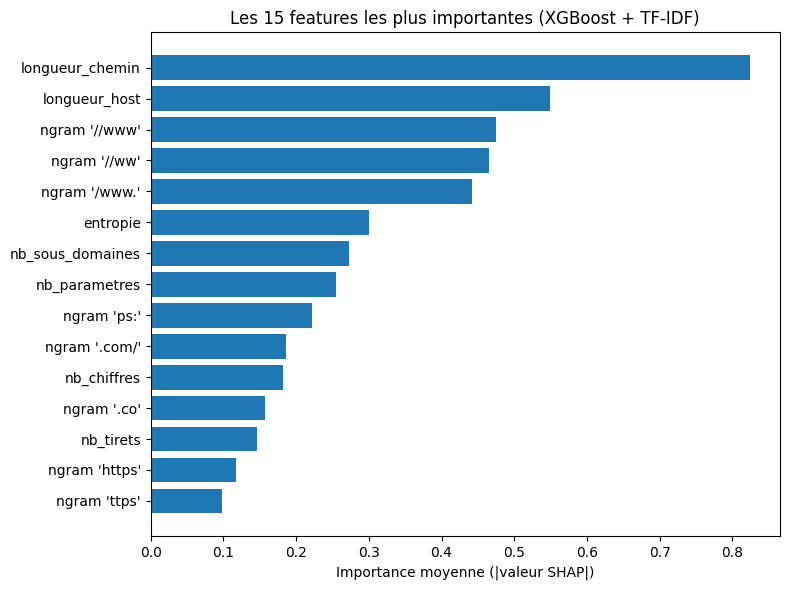

In [ ]:
import xgboost as xgb_lib
import numpy as np
import matplotlib.pyplot as plt

# Noms des features : les 13 features + les n-grammes TF-IDF
noms = list(X_train.columns) + [f"ngram '{g}'" for g in tfidf.get_feature_names_out()]

# Valeurs SHAP calculées par XGBoost (TreeSHAP) sur 1 000 URLs de la validation
echantillon = Xc_val[:1000]
dm = xgb_lib.DMatrix(echantillon, feature_names=None)
shap_vals = xgb_tfidf.get_booster().predict(dm, pred_contribs=True)[:, :-1]  # la dernière colonne = biais

# Importance moyenne de chaque feature
importance = pd.Series(np.abs(shap_vals).mean(axis=0), index=noms).sort_values(ascending=False)
top = importance.head(15)[::-1]

plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values)
plt.xlabel("Importance moyenne (|valeur SHAP|)")
plt.title("Les 15 features les plus importantes (XGBoost + TF-IDF)")
plt.tight_layout()
plt.savefig(f"{MODELS}/shap_top15_links.png", dpi=150)
plt.show()

## Étape 6.5 : Sauvegarde du modèle

Le modèle final du module liens est XGBoost + TF-IDF avec un seuil de 0,221.
On sauvegarde dans le Drive tout ce qu'il faut pour le réutiliser plus tard (dans l'API et la démo) :
le vectoriseur TF-IDF, le modèle XGBoost, le seuil, la liste des features et les résultats.

In [ ]:
import joblib, json

# Sauvegarder le vectoriseur, le modèle et le seuil
joblib.dump(tfidf, f"{MODELS}/links_tfidf.joblib")
joblib.dump(xgb_tfidf, f"{MODELS}/links_xgb_tfidf.joblib")

infos = {
    "modele": "XGBoost + TF-IDF (char 3-5, 20000)",
    "seuil": SEUIL,
    "features": list(X_train.columns),
    "donnees": "PhreshPhish (train 2024-07 → 2025-09, test 2025-09 → 2025-12)",
}
with open(f"{MODELS}/links_infos.json", "w") as f:
    json.dump(infos, f, indent=2, ensure_ascii=False)

# Sauvegarder les tableaux de résultats pour la présentation
resultats.round(3).to_csv(f"{MODELS}/links_resultats_validation.csv")
final.round(3).to_csv(f"{MODELS}/links_resultats_test.csv")
comparaison.round(3).to_csv(f"{MODELS}/links_domaines_vus_vs_nouveaux.csv")

print("Fichiers dans models/ :")
for f in sorted(os.listdir(MODELS)):
    print(" -", f)

Fichiers dans models/ :
 - links_domaines_vus_vs_nouveaux.csv
 - links_infos.json
 - links_resultats_test.csv
 - links_resultats_validation.csv
 - links_tfidf.joblib
 - links_xgb_tfidf.joblib
 - shap_top15_links.png


## Étape 6.6 : Démonstration

Une fonction qui prend une URL et renvoie :
- un score entre 0 et 1,
- un verdict à 3 niveaux : SÛR (score < 0,221), SUSPECT (entre 0,221 et 0,5), DANGEREUX (≥ 0,5),
- les 3 raisons principales (contributions SHAP).
L'URL n'est jamais ouverte : on analyse seulement le texte du lien.
On teste aussi l'ajout de "www." pour vérifier la faiblesse vue avec SHAP.

In [ ]:
def verifier_url(url):
    # Mêmes transformations que pour l'entraînement
    X1 = pd.DataFrame([features_url(url)])
    Xc1 = hstack([csr_matrix(X1.values), tfidf.transform([url])]).tocsr()
    score = float(xgb_tfidf.predict_proba(Xc1)[:, 1][0])

    if score >= 0.5:
        verdict = "DANGEREUX"
    elif score >= SEUIL:
        verdict = "SUSPECT"
    else:
        verdict = "SUR"

    # Les 3 features qui ont le plus poussé vers "phishing"
    contrib = xgb_tfidf.get_booster().predict(xgb_lib.DMatrix(Xc1), pred_contribs=True)[0, :-1]
    raisons = pd.Series(contrib, index=noms).sort_values(ascending=False).head(3)
    raisons = [f"{n} (+{v:.2f})" for n, v in raisons.items() if v > 0]

    print(f"{url}\n  score = {score:.3f} -> {verdict}")
    if raisons:
        print("  raisons :", ", ".join(raisons))
    print()

# URLs de test (les liens suspects sont inventés, ils ne sont jamais ouverts)
verifier_url("https://www.amazon.com/gp/your-account/order-history")
verifier_url("https://github.com/ilyassboudrioua/qr-shield-mlops")
verifier_url("http://secure-login-paypa1-verify.top/account/update?id=93821")
verifier_url("https://appleid-unlock-support2025.xyz/signin")

# Test de la faiblesse "www." : le même lien suspect, avec www. ajouté
verifier_url("http://www.secure-login-paypa1-verify.top/account/update?id=93821")

https://www.amazon.com/gp/your-account/order-history
  score = 0.001 -> SUR
  raisons : ngram '-ac' (+0.50), nb_mots_suspects (+0.29), longueur_url (+0.05)

https://github.com/ilyassboudrioua/qr-shield-mlops
  score = 0.024 -> SUR
  raisons : nb_sous_domaines (+0.32), ngram '//www' (+0.23), ngram '//ww' (+0.20)

http://secure-login-paypa1-verify.top/account/update?id=93821
  score = 1.000 -> DANGEREUX
  raisons : nb_parametres (+2.84), longueur_host (+0.92), ngram 'verif' (+0.74)

https://appleid-unlock-support2025.xyz/signin
  score = 0.998 -> DANGEREUX
  raisons : ngram 'xyz' (+1.00), longueur_host (+0.93), longueur_chemin (+0.72)

http://www.secure-login-paypa1-verify.top/account/update?id=93821
  score = 1.000 -> DANGEREUX
  raisons : nb_parametres (+3.47), longueur_host (+1.31), ngram 'verif' (+0.78)



## Étape 6.7 : Vérification d'un deuxième raccourci possible

SHAP montre que la présence d'un paramètre (`?id=...`) pousse très fort vers "phishing".
Or les URLs sûres du train n'ont presque jamais de paramètres.
On vérifie si c'est un vrai signe de phishing ou une particularité de la collecte des données.

In [ ]:
a_param = train_clean["url"].str.contains(r"\?", regex=True)

print("Part des URLs avec paramètres ('?') :")
print(train_clean.assign(a_param=a_param).groupby("label")["a_param"].mean().round(4))

print("\nNombre d'URLs sûres avec paramètres :", (a_param & (train_clean["label"] == "benign")).sum())
print("Nombre d'URLs phishing avec paramètres :", (a_param & (train_clean["label"] == "phish")).sum())

print("\nExemples d'URLs sûres avec paramètres :")
print(train_clean[a_param & (train_clean["label"] == "benign")]["url"].head(5).to_string())

Part des URLs avec paramètres ('?') :
label
benign    0.0001
phish     0.0727
Name: a_param, dtype: float64

Nombre d'URLs sûres avec paramètres : 3
Nombre d'URLs phishing avec paramètres : 3227

Exemples d'URLs sûres avec paramètres :
66067    https://compliance.login.globalrelay.com/cc/ar...
77157    https://retaillink.login.wal-mart.com/?resumeP...
95353    https://security.firsthorizon.com/fhnsso/clogi...


## Étape 6.8 : Correction du raccourci "paramètres" et réentraînement

Les URLs sûres du dataset n'ont presque jamais de paramètres (0,01 %), contre 7,3 % pour le phishing.
C'est une particularité de la collecte, pas un vrai signe d'attaque.
Correction : on retire les paramètres ("?..." et "#...") de toutes les URLs, on supprime la feature nb_parametres,
puis on refait les mêmes étapes : features, TF-IDF, XGBoost, choix du seuil sur la validation, mesure unique sur le test.

In [ ]:
# 1. Retirer les paramètres et les ancres de toutes les URLs
def sans_parametres(url):
    return url.split("?")[0].split("#")[0]

urls_train2 = train_clean["url"].map(sans_parametres)
urls_test2 = test_clean["url"].map(sans_parametres)

# 2. Recalculer les features (sans nb_parametres)
X_train2 = pd.DataFrame([features_url(u) for u in urls_train2]).drop(columns="nb_parametres")
X_test2 = pd.DataFrame([features_url(u) for u in urls_test2]).drop(columns="nb_parametres")

# 3. Même découpage train / validation par date qu'avant
X_tr2, X_val2 = X_train2[~est_val], X_train2[est_val]

# 4. TF-IDF appris sur le train seulement
tfidf2 = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), max_features=20000, min_df=5)
Xc_tr2 = hstack([csr_matrix(X_tr2.values), tfidf2.fit_transform(urls_train2[~est_val])]).tocsr()
Xc_val2 = hstack([csr_matrix(X_val2.values), tfidf2.transform(urls_train2[est_val])]).tocsr()
Xc_test2 = hstack([csr_matrix(X_test2.values), tfidf2.transform(urls_test2)]).tocsr()

# 5. Réentraîner XGBoost
xgb2 = XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.1, subsample=0.8,
                     colsample_bytree=0.8, tree_method="hist", eval_metric="logloss",
                     random_state=42, n_jobs=-1)
xgb2.fit(Xc_tr2, y_tr)

# 6. Nouveau seuil sur la validation (même budget : FPR <= 5 %)
proba_val2 = xgb2.predict_proba(Xc_val2)[:, 1]
fpr2, tpr2, s2 = roc_curve(y_val, proba_val2)
ok2 = fpr2 <= 0.05
SEUIL2 = float(s2[ok2][tpr2[ok2].argmax()])
print("Nouveau seuil :", round(SEUIL2, 3))

# 7. Comparer l'ancien et le nouveau modèle, sur la validation et sur le test
proba_test2 = xgb2.predict_proba(Xc_test2)[:, 1]
comparatif = pd.DataFrame([
    evaluer("Validation - avant correction", y_val, proba_val, seuil=SEUIL),
    evaluer("Validation - après correction", y_val, proba_val2, seuil=SEUIL2),
    evaluer("Test - avant correction", y_test, xgb_tfidf.predict_proba(Xc_test)[:, 1], seuil=SEUIL),
    evaluer("Test - après correction", y_test, proba_test2, seuil=SEUIL2),
]).set_index("Modèle")
comparatif[["TP", "FN", "FP", "TN", "Recall", "Precision", "FPR", "MCC", "ROC-AUC"]].round(3)

Nouveau seuil : 0.256


,TP,FN,FP,TN,Recall,Precision,FPR,MCC,ROC-AUC
Modèle,,,,,,,,,
Validation - avant correction,4449,1138,688,13205,0.796,0.866,0.050,0.766,0.910
Validation - après correction,4275,1312,694,13199,0.765,0.860,0.050,0.742,0.898
Test - avant correction,12706,1043,1083,14879,0.924,0.921,0.068,0.856,0.976
Test - après correction,12536,1213,1064,14898,0.912,0.922,0.067,0.846,0.971


## Étape 6.9 : Sauvegarde du modèle corrigé (version 2)
On enregistre le nouveau modèle (sans le raccourci "paramètres") pour ne pas avoir à le réentraîner.

In [ ]:
joblib.dump(tfidf2, f"{MODELS}/links_tfidf_v2.joblib")
joblib.dump(xgb2, f"{MODELS}/links_xgb_v2.joblib")

infos_v2 = {
    "modele": "XGBoost + TF-IDF v2 (URLs sans paramètres, sans nb_parametres)",
    "seuil": SEUIL2,
    "features": list(X_train2.columns),
}
with open(f"{MODELS}/links_infos_v2.json", "w") as f:
    json.dump(infos_v2, f, indent=2, ensure_ascii=False)

comparatif.round(3).to_csv(f"{MODELS}/links_avant_apres_correction.csv")
print("Modèle v2 sauvegardé")

Modèle v2 sauvegardé
